# Seeded Weekly Comparison — DQN vs DQN No-LLM vs Buy & Hold

**Test period:** 2024-01-05 → 2026-02-02  |  Weekly rebalancing  |  10% stop-loss  |  5 seeds  |  $10,000 starting capital

DQN / No-LLM / **Buy and Hold return %** are read from `test_results/seeded_weekly_full/seeded_weekly_async_by_ticker.csv`. **Prices and date range** for the preview row still come from `data/*_weekly_stock_data.csv`.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Async multi-seed summary (wide CSV: one row per ticker). Edit the file to update numbers.
ASYNC_CSV = 'test_results/seeded_weekly_full/seeded_weekly_async_by_ticker.csv'


def _summary_from_async_csv(wide: pd.DataFrame):
    rows = []
    for _, r in wide.iterrows():
        t = r['ticker']
        runs = int(r['runs']) if 'runs' in wide.columns and pd.notna(r['runs']) else 5
        rows.append({
            'ticker': t, 'method': 'dqn', 'runs': runs,
            'return_mean_pct': r['dqn_return_mean'], 'return_std_pct': r['dqn_return_std'],
            'final_mean': np.nan, 'final_std': np.nan,
            'sharpe_mean': r['dqn_sharpe_mean'], 'sharpe_std': r['dqn_sharpe_std'],
            'win_rate_mean': np.nan, 'win_rate_std': np.nan,
            'max_drawdown_mean': r['dqn_maxdd_mean'], 'max_drawdown_std': r['dqn_maxdd_std'],
            'return_max_pct': r['dqn_max_return'],
        })
        rows.append({
            'ticker': t, 'method': 'dqn_nollm', 'runs': runs,
            'return_mean_pct': r['nollm_return_mean'], 'return_std_pct': r['nollm_return_std'],
            'final_mean': np.nan, 'final_std': np.nan,
            'sharpe_mean': r['nollm_sharpe_mean'], 'sharpe_std': r['nollm_sharpe_std'],
            'win_rate_mean': np.nan, 'win_rate_std': np.nan,
            'max_drawdown_mean': r['nollm_maxdd_mean'], 'max_drawdown_std': r['nollm_maxdd_std'],
            'return_max_pct': r['nollm_max_return'],
        })
    return pd.DataFrame(rows)


_async_wide = pd.read_csv(ASYNC_CSV)
_BAH_RET = dict(zip(_async_wide['ticker'], _async_wide['bah_pct']))
summary = _summary_from_async_csv(_async_wide)
TICKERS = sorted(summary['ticker'].unique())
START_DATE = '2024-01-01'

# ── Buy & Hold: first/last adjusted_close on or after START_DATE ─────────────
bah = {}
for t in TICKERS:
    path = f'data/{t}_weekly_stock_data.csv'
    if not os.path.exists(path):
        bah[t] = dict(ret=np.nan, start_date='N/A', end_date='N/A', start_price=np.nan, end_price=np.nan)
        continue
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    df = df[df.index >= START_DATE].sort_index().dropna(subset=['adjusted_close'])
    p0, p1 = df['adjusted_close'].iloc[0], df['adjusted_close'].iloc[-1]
    bah[t] = dict(
        ret=round((p1/p0 - 1)*100, 2),
        start_date=str(df.index[0].date()),
        end_date=str(df.index[-1].date()),
        start_price=round(p0, 2),
        end_price=round(p1, 2),
    )

bah_df = pd.DataFrame(bah).T.reset_index().rename(columns={'index': 'ticker'})
for t in TICKERS:
    bah_df.loc[bah_df['ticker'] == t, 'ret'] = _BAH_RET[t]

print(f"Test window: {bah_df['start_date'].iloc[0]}  →  {bah_df['end_date'].iloc[0]}")
bah_df[['ticker', 'start_date', 'end_date', 'start_price', 'end_price', 'ret']].rename(
    columns={'ret': 'bah_return_pct'}
)


Test window: 2024-01-05  →  2026-02-02


,ticker,start_date,end_date,start_price,end_price,bah_return_pct
0,AAPL,2024-01-05,2026-02-02,179.5,270.01,50.42
1,AMZN,2024-01-05,2026-02-02,145.24,242.96,67.28
2,ASML,2024-01-05,2026-02-02,688.27,1441.39,109.42
3,GOOGL,2024-01-05,2026-02-02,134.7,343.69,155.14
4,META,2024-01-05,2026-02-02,349.53,706.41,102.1
5,MSFT,2024-01-05,2026-02-02,362.36,423.37,16.84
6,NVDA,2024-01-05,2026-02-02,49.07,185.61,278.26
7,TSLA,2024-01-05,2026-02-02,237.49,421.81,77.61
8,TSM,2024-01-05,2026-02-02,96.94,341.36,252.14


In [2]:
def fmt(mean, std, dm=2, ds=None):
    if pd.isna(mean) or pd.isna(std):
        return "—"
    if ds is None:
        ds = dm
    return f"{mean:.{dm}f} ± {std:.{ds}f}"


def best(dqn_val, nollm_val, bah_val=None, lower_is_better=False):
    vals = {'DQN': dqn_val, 'No-LLM': nollm_val}
    if bah_val is not None:
        vals['B&H'] = bah_val
    vals = {k: v for k, v in vals.items() if pd.notna(v)}
    if not vals:
        return '—'
    winner = (min if lower_is_better else max)(vals, key=vals.get)
    return {'DQN': '🟦', 'No-LLM': '⬜', 'B&H': '🟨'}[winner]


s = summary.set_index(['ticker', 'method'])

rows = []
for t in TICKERS:
    d = s.loc[(t, 'dqn')]
    nl = s.loc[(t, 'dqn_nollm')]
    bh = float(bah_df.set_index('ticker').loc[t, 'ret'])
    wr_star = (
        best(d['win_rate_mean'], nl['win_rate_mean'])
        if pd.notna(d['win_rate_mean']) or pd.notna(nl['win_rate_mean'])
        else '—'
    )
    rows.append({
        'Ticker': t,
        'B&H Return %': f"{bh:.2f}%",
        'DQN Return %': fmt(d['return_mean_pct'], d['return_std_pct'], dm=2, ds=2) + '%',
        'No-LLM Return %': fmt(nl['return_mean_pct'], nl['return_std_pct'], dm=2, ds=2) + '%',
        '★ Return': best(d['return_mean_pct'], nl['return_mean_pct'], bh),
        'DQN Sharpe': fmt(d['sharpe_mean'], d['sharpe_std'], dm=2, ds=2),
        'No-LLM Sharpe': fmt(nl['sharpe_mean'], nl['sharpe_std'], dm=2, ds=2),
        '★ Sharpe': best(d['sharpe_mean'], nl['sharpe_mean']),
        'DQN MaxDD %': fmt(d['max_drawdown_mean'], d['max_drawdown_std'], dm=1, ds=1),
        'No-LLM MaxDD %': fmt(nl['max_drawdown_mean'], nl['max_drawdown_std'], dm=1, ds=1),
        '★ MaxDD': best(d['max_drawdown_mean'], nl['max_drawdown_mean'], lower_is_better=True),
        'DQN Win Rate %': fmt(d['win_rate_mean'], d['win_rate_std']),
        'No-LLM Win Rate %': fmt(nl['win_rate_mean'], nl['win_rate_std']),
        '★ Win Rate': wr_star,
    })

display(pd.DataFrame(rows).set_index('Ticker'))
print('\n🟦 DQN (LLM)   ⬜ No-LLM   🟨 Buy & Hold')


,B&H Return %,DQN Return %,No-LLM Return %,★ Return,DQN Sharpe,No-LLM Sharpe,★ Sharpe,DQN MaxDD %,No-LLM MaxDD %,★ MaxDD,DQN Win Rate %,No-LLM Win Rate %,★ Win Rate
Ticker,,,,,,,,,,,,,
AAPL,50.4%,43.1 ± 29.4%,27.2 ± 19.5%,🟨,1.90 ± 1.05,1.38 ± 0.55,🟦,20.0 ± 11.0,22.2 ± 12.7,🟦,—,—,—
AMZN,67.3%,43.4 ± 27.1%,28.4 ± 10.1%,🟨,1.90 ± 1.02,1.40 ± 0.53,🟦,21.1 ± 9.5,24.0 ± 5.9,🟦,—,—,—
ASML,109.4%,88.3 ± 38.3%,24.3 ± 21.7%,🟨,1.45 ± 0.28,1.10 ± 0.64,🟦,32.3 ± 13.8,31.8 ± 13.0,⬜,—,—,—
GOOGL,155.1%,104.2 ± 18.7%,79.7 ± 49.4%,🟨,3.37 ± 0.51,2.49 ± 1.30,🟦,22.8 ± 6.7,28.4 ± 11.1,🟦,—,—,—
META,102.1%,45.1 ± 18.6%,14.1 ± 26.1%,🟨,1.71 ± 0.49,0.41 ± 1.56,🟦,33.5 ± 1.1,32.6 ± 1.7,⬜,—,—,—
MSFT,16.8%,-3.1 ± 11.6%,-3.5 ± 15.5%,🟨,0.03 ± 0.63,0.16 ± 1.08,⬜,21.4 ± 1.6,21.9 ± 8.4,🟦,—,—,—
NVDA,278.3%,111.0 ± 62.2%,90.0 ± 89.3%,🟨,2.49 ± 0.98,2.08 ± 1.72,🟦,27.1 ± 7.7,27.2 ± 11.7,🟦,—,—,—
TSLA,77.6%,66.8 ± 63.4%,32.1 ± 48.9%,🟨,1.52 ± 1.05,0.53 ± 1.55,🟦,33.3 ± 6.2,38.9 ± 8.5,🟦,—,—,—
TSM,252.1%,82.7 ± 40.3%,87.2 ± 35.3%,🟨,2.78 ± 0.78,2.67 ± 0.60,🟦,24.0 ± 6.3,27.6 ± 7.2,🟦,—,—,—



🟦 DQN (LLM)   ⬜ No-LLM   🟨 Buy & Hold


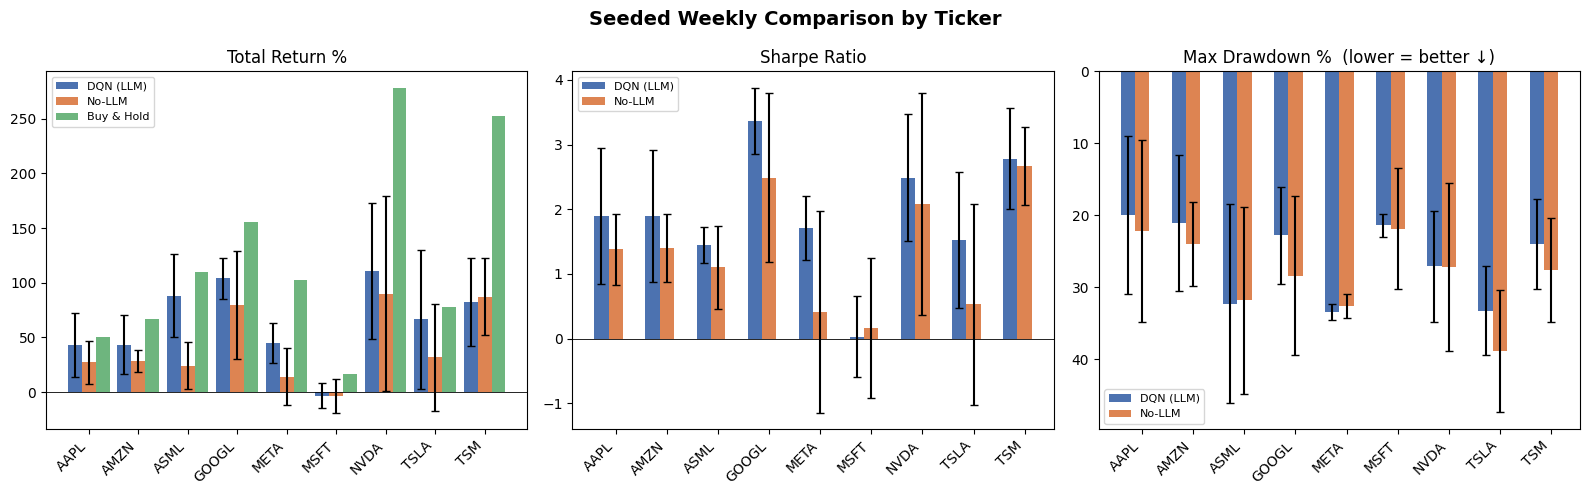

In [3]:
dqn   = summary[summary['method']=='dqn'].set_index('ticker').loc[TICKERS]
nollm = summary[summary['method']=='dqn_nollm'].set_index('ticker').loc[TICKERS]
bah_ret = [float(bah_df.set_index('ticker').loc[t, 'ret']) for t in TICKERS]

x = np.arange(len(TICKERS))
w = 0.28
c_dqn, c_nollm, c_bah = '#4C72B0', '#DD8452', '#55A868'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Seeded Weekly Comparison by Ticker', fontsize=14, fontweight='bold')

panels = [
    ('Total Return %', 'return_mean_pct', 'return_std_pct', False),
    ('Sharpe Ratio', 'sharpe_mean', 'sharpe_std', False),
    ('Max Drawdown %', 'max_drawdown_mean', 'max_drawdown_std', True),
]

for ax, (title, col, std_col, invert) in zip(axes, panels):
    ax.bar(x - w, dqn[col], w, yerr=dqn[std_col], capsize=3, label='DQN (LLM)', color=c_dqn)
    ax.bar(x, nollm[col], w, yerr=nollm[std_col], capsize=3, label='No-LLM', color=c_nollm)
    if title == 'Total Return %':
        ax.bar(x + w, bah_ret, w, label='Buy & Hold', color=c_bah, alpha=0.85)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(TICKERS, rotation=45, ha='right')
    ax.axhline(0, color='black', linewidth=0.6)
    ax.legend(fontsize=8)
    if invert:
        ax.invert_yaxis()
        ax.set_title(title + '  (lower = better ↓)')

plt.tight_layout()
plt.show()


In [4]:
print("=== Score Card ===\n")

dqn_wins_ret = sum(dqn.loc[t, 'return_mean_pct'] > nollm.loc[t, 'return_mean_pct'] for t in TICKERS)
dqn_wins_sr = sum(dqn.loc[t, 'sharpe_mean'] > nollm.loc[t, 'sharpe_mean'] for t in TICKERS)
dqn_wins_wr = sum(
    pd.notna(dqn.loc[t, 'win_rate_mean']) and pd.notna(nollm.loc[t, 'win_rate_mean'])
    and dqn.loc[t, 'win_rate_mean'] > nollm.loc[t, 'win_rate_mean']
    for t in TICKERS
)
dqn_wins_dd = sum(dqn.loc[t, 'max_drawdown_mean'] < nollm.loc[t, 'max_drawdown_mean'] for t in TICKERS)

n = len(TICKERS)
if dqn['win_rate_mean'].notna().any():
    print(
        f"DQN (LLM) beats No-LLM  →  Return: {dqn_wins_ret}/{n}  |  Sharpe: {dqn_wins_sr}/{n}  "
        f"|  Win Rate: {dqn_wins_wr}/{n}  |  Lower MaxDD: {dqn_wins_dd}/{n}"
    )
else:
    print(
        f"DQN (LLM) beats No-LLM  →  Return: {dqn_wins_ret}/{n}  |  Sharpe: {dqn_wins_sr}/{n}  "
        f"|  Lower MaxDD: {dqn_wins_dd}/{n}"
    )
    print("(Win rate not in async summary export.)")

dqn_bah_beat = sum(dqn.loc[t, 'return_mean_pct'] > float(bah_df.set_index('ticker').loc[t, 'ret']) for t in TICKERS)
nollm_bah_beat = sum(nollm.loc[t, 'return_mean_pct'] > float(bah_df.set_index('ticker').loc[t, 'ret']) for t in TICKERS)
print(f"Beats Buy & Hold         →  DQN: {dqn_bah_beat}/{n}  |  No-LLM: {nollm_bah_beat}/{n}")

print("\nAverages across all tickers:")
print(f"  Sharpe    — DQN: {dqn['sharpe_mean'].mean():.2f}  |  No-LLM: {nollm['sharpe_mean'].mean():.2f}")
print(f"  MaxDD %   — DQN: {dqn['max_drawdown_mean'].mean():.1f}  |  No-LLM: {nollm['max_drawdown_mean'].mean():.1f}")
if dqn['win_rate_mean'].notna().any():
    print(f"  Win Rate% — DQN: {dqn['win_rate_mean'].mean():.1f}  |  No-LLM: {nollm['win_rate_mean'].mean():.1f}")

=== Score Card ===

DQN (LLM) beats No-LLM  →  Return: 8/9  |  Sharpe: 8/9  |  Lower MaxDD: 7/9
(Win rate not in async summary export.)
Beats Buy & Hold         →  DQN: 0/9  |  No-LLM: 0/9

Averages across all tickers:
  Sharpe    — DQN: 1.91  |  No-LLM: 1.36
  MaxDD %   — DQN: 26.2  |  No-LLM: 28.3


In [5]:
pivot = summary.pivot(index='ticker', columns='method', values='return_max_pct').loc[TICKERS]
pivot = pivot.rename(columns={'dqn': 'DQN (LLM) max%', 'dqn_nollm': 'No-LLM max%'})
pivot['Winner'] = pivot.apply(
    lambda r: '🟦 DQN' if r['DQN (LLM) max%'] > r['No-LLM max%'] else '⬜ No-LLM', axis=1
)
pivot['Gap'] = (pivot['DQN (LLM) max%'] - pivot['No-LLM max%']).round(1).apply(
    lambda v: f"+{v}" if v > 0 else str(v)
)
display(pivot.round(1))

method,DQN (LLM) max%,No-LLM max%,Winner,Gap
ticker,,,,
AAPL,79.1,48.6,🟦 DQN,+30.5
AMZN,61.7,36.5,🟦 DQN,+25.2
ASML,133.8,79.7,🟦 DQN,+54.1
GOOGL,132.5,127.8,🟦 DQN,+4.7
META,76.8,35.2,🟦 DQN,+41.6
MSFT,8.6,-0.1,🟦 DQN,+8.7
NVDA,190.5,165.7,🟦 DQN,+24.8
TSLA,142.3,84.9,🟦 DQN,+57.4
TSM,147.1,126.3,🟦 DQN,+20.8
